In [1]:
import csv
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from tabulate import tabulate
from collections import defaultdict
from matplotlib import pyplot as plt
from matplotlib.ticker import FormatStrFormatter
import re
from scipy.spatial.distance import mahalanobis
from scipy.stats import chi2
import copy
# import tensorflow as tf

In [2]:
# Loading the datase
dataset = pd.read_csv("augmented_df_data.csv")
backup_df = copy.deepcopy(dataset)
data_df = dataset.drop(['Replicate', 'Conc.', 'batch', 'Unnamed: 0'], axis=1)

print('variants:', data_df.target_vector.unique())

data_df.head()

variants: ['Beta' 'Delta' 'Omicron' 'WT']


,target_vector,cAb7,cAb8,cAb9,cAb10,cAb13,cAb14,cAb15,cAb20,cAb21,cAb25,cAb26
0,Beta,3.922,3.410,2.164,1.631,2.148,2.601,2.572,4.168,3.982,3.195,4.268
1,Beta,3.679,2.986,1.279,0.942,1.873,2.034,1.625,3.737,3.520,2.679,3.716
2,Beta,3.283,2.540,1.378,0.000,1.867,1.362,1.016,3.282,3.212,2.219,3.286
3,Beta,2.805,2.188,0.000,0.000,0.000,0.000,0.000,2.903,2.485,1.715,2.970
4,Beta,2.881,2.079,0.000,0.000,0.000,0.512,0.495,2.508,2.282,1.575,2.779


In [3]:
# Global parameters
default_test_size = 0.3
debug = False
print_descriptions = True
random_state=2023
targets_list = data_df.target_vector.unique()

In [4]:
# Data Handling functions
def Xy_split(df, y_column_name='target_vector'):
    X = df.loc[:, df.columns != y_column_name]
    y = df[y_column_name]
    return X, y

def target_split(df, target_name):
    df_no_target = df.loc[df["target_vector"] != target_name]
    df_target = df.loc[df["target_vector"] == target_name]
    return df_no_target, df_target


# Test/Train/Target split!
def test_train_target_split(df, target_variant, test_size=default_test_size):
    global debug
    
    print(f'test/train split size = {test_size}') if debug else None
    print(f'target variant = {target_variant}') if print_descriptions else None
    
    no_target, target = target_split(df=df, target_name=target_variant)
    no_target_train, no_target_test = train_test_split(no_target, test_size=test_size, random_state=2023)

    out_dict = {'non_target_train_samples': no_target_train,
                'non_target_test_samples': no_target_test,
                'target_samples': target,
                'non_target_samples': no_target
               }
    
    print(f'dataset: {df.shape}') if debug else None
    for k, d in out_dict.items():
        r, c = d.shape
        print(f"{k}: {r} x {c}") if print_descriptions else None
    return out_dict


def calculate_prefromance(results, description=None):
    L = len(results)
    sum_true_preds = sum(results['real'] == results['final_pred'])
    performance = 100*sum_true_preds/L
    
    if description:
        print(f'{description}-> {performance:.2f}% [{sum_true_preds}/{L}]')
    return performance


In [11]:
def train_model(X, y, target, **kwargs):
    global random_state
    
    method = kwargs.pop('method', None)
    
    if method == "LogReg":
        model = LogisticRegression(**kwargs, random_state=random_state)
    elif method == "RFC":
        model = RandomForestClassifier(**kwargs, random_state=random_state)
    else:
        print("I don't know this method :(")
        return None
    
    model.fit(X, y)
    return model


def get_test_results(model, test_df, target, thr):
    global debug
    
    X, y = Xy_split(test_df)
    
    # these two lines works for current methods, but might need modification for future models
    y_pred = model.predict(X)
    y_pred_prob = model.predict_proba(X)

    results = pd.DataFrame(y_pred_prob, columns=model.classes_)
    results['real'] = list(y)
    results['model_pred'] = y_pred
    results['model_confidence'] = y_pred_prob.max(axis=1)
    results['is_confident'] = y_pred_prob.max(axis=1) > thr 
    results['final_pred'] = results.apply(lambda row: row['model_pred'] if row['is_confident'] else target, axis=1)
    
    col_order = list(model.classes_) + ['real', 'model_pred', 'final_pred', 'model_confidence', 'is_confident']
    results = results[col_order]
#     print(results.head()) if debug else None
    return results


def test_model_on_1target(input_df, target, **kwargs):
    global debug, print_descriptions, default_test_size
    print('-------')  if print_descriptions else None
    
    thr_list = kwargs.pop('thr_list', None)
    test_size = kwargs.pop('test_size', None)
    
    data_dict = test_train_target_split(df=input_df, target_variant=target, test_size=test_size)
    train_X, train_y = Xy_split(data_dict['non_target_train_samples'])

    nt_perf = []
    t_perf = []

    model = train_model(X=train_X, y=train_y, target=target, **kwargs)

    for thr in thr_list:
        nt_results = get_test_results(model, data_dict['non_target_test_samples'], target, thr)
        t_results = get_test_results(model, data_dict['target_samples'], target, thr)
        
        nt_perf.append(calculate_prefromance(nt_results))
        t_perf.append(calculate_prefromance(t_results))
        
        print(f'({thr}) nt:\n{nt_results.head()}\n\n({thr}) t:\n{t_results.head()}') if debug else None
        
        
    return nt_perf, t_perf


def show_scan_results(nt_pref_df, t_pref_df, **kwargs):
    global print_descriptions
    
    thr_list = kwargs.pop('thr_list', None)
    nt_pref_df.index = thr_list
    t_pref_df.index = thr_list
    
    print('\nperformance on non-target test dataset:\n', nt_pref_df) if print_descriptions else None
    print('\nperformance on target dataset:\n', t_pref_df) if print_descriptions else None
    
    fig, axes = plt.subplots(2,1, figsize=(10, 5)) 
    nt_pref_df.plot.bar(ax=axes[0], rot=0,width=0.5)
    t_pref_df.plot.bar(ax=axes[1], rot=0, width=0.5)
    fig.text(0.5, 0.02, 'Confidence Threshold', ha='center')
    fig.text(0.07, 0.5, 'Accuracy', va='center', rotation='vertical')
    return 


def run_thr_scan(input_df, **kwargs):
    global targets_list
    
    features_vec = [col for col in input_df.columns if col != 'target_vector']
    additional_columns = set(input_df.columns) - set(features_vec) - {'target_vector'}
    if len(additional_columns) > 0:
        print(f'these columns should not be here: {additional_columns}')
        
    nt_pref_df = pd.DataFrame()
    t_pref_df = pd.DataFrame()
    
    for target in targets_list:
        nt_perf, t_perf = test_model_on_1target(input_df=input_df, target=target, **kwargs)
        nt_pref_df[target] = nt_perf 
        t_pref_df[target] = t_perf
    show_scan_results(nt_pref_df, t_pref_df, **kwargs)
    return nt_pref_df, t_pref_df


### Logistic Regresion model

-------
target variant = Beta
non_target_train_samples: 544 x 12
non_target_test_samples: 182 x 12
target_samples: 282 x 12
non_target_samples: 726 x 12
-------
target variant = Delta
non_target_train_samples: 616 x 12
non_target_test_samples: 206 x 12
target_samples: 186 x 12
non_target_samples: 822 x 12
-------
target variant = Omicron
non_target_train_samples: 562 x 12
non_target_test_samples: 188 x 12
target_samples: 258 x 12
non_target_samples: 750 x 12
-------
target variant = WT
non_target_train_samples: 544 x 12
non_target_test_samples: 182 x 12
target_samples: 282 x 12
non_target_samples: 726 x 12

performance on non-target test dataset:
           Beta      Delta    Omicron         WT
0.0  67.032967  54.368932  56.382979  55.494505
0.1  67.032967  54.368932  56.382979  55.494505
0.2  67.032967  54.368932  56.382979  55.494505
0.3  67.032967  54.368932  56.382979  55.494505
0.4  64.835165  51.941748  50.531915  53.296703
0.5  54.945055  38.349515  42.021277  40.659341
0.6  39.

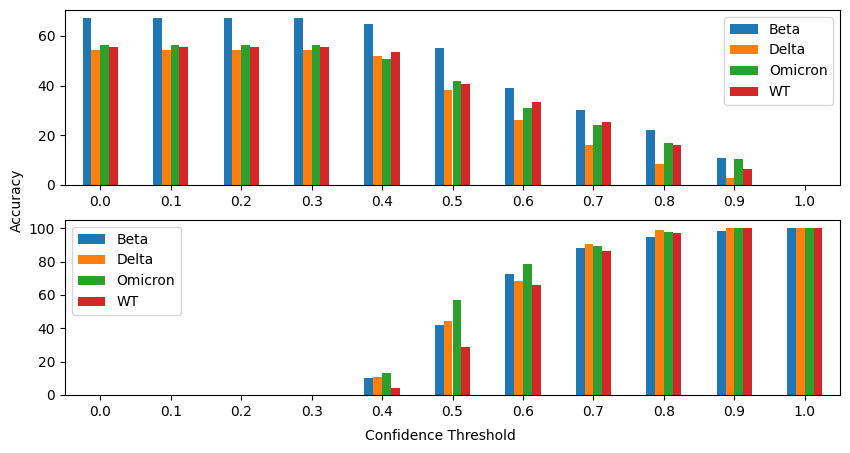

In [12]:
# input_df = data_df.loc[:, ['target_vector', 'cAb7', 'cAb14', 'cAb21', 'cAb26']]
# features_vec = ['cAb7', 'cAb14', 'cAb21', 'cAb26']
input_df = data_df

params = {'method': 'LogReg',
          'max_iter': 1000,
          "thr_list": [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
         }

LR_nt_pref, LR_t_perf = run_thr_scan(input_df, **params)


### Random Forrest Classifier

-------
target variant = Beta
non_target_train_samples: 580 x 5
non_target_test_samples: 146 x 5
target_samples: 282 x 5
non_target_samples: 726 x 5
-------
target variant = Delta
non_target_train_samples: 657 x 5
non_target_test_samples: 165 x 5
target_samples: 186 x 5
non_target_samples: 822 x 5
-------
target variant = Omicron
non_target_train_samples: 600 x 5
non_target_test_samples: 150 x 5
target_samples: 258 x 5
non_target_samples: 750 x 5
-------
target variant = WT
non_target_train_samples: 580 x 5
non_target_test_samples: 146 x 5
target_samples: 282 x 5
non_target_samples: 726 x 5

performance on non-target test dataset:
           Beta      Delta    Omicron         WT
0.0  74.657534  69.696970  65.333333  78.082192
0.1  74.657534  69.696970  65.333333  78.082192
0.2  74.657534  69.696970  65.333333  78.082192
0.3  74.657534  69.696970  65.333333  78.082192
0.4  74.657534  69.696970  64.666667  77.397260
0.5  67.808219  62.424242  60.000000  68.493151
0.6  62.328767  50.90909

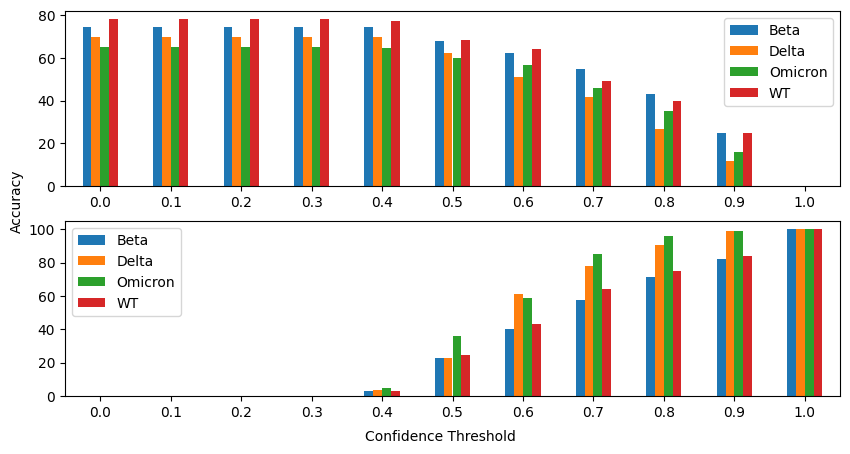

In [16]:
input_df = data_df.loc[:, ['target_vector', 'cAb7', 'cAb14', 'cAb21', 'cAb26']]
features_vec = ['cAb7', 'cAb14', 'cAb21', 'cAb26']
# input_df = data_df

debug = False
 
params = {'method': "RFC",
          'n_estimators': 500,
          'thr_list': [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1],
          'test_size': 0.2
         }

RFC_nt_pref, RFC_t_perf = run_thr_scan(input_df, **params)


In [174]:
data_dict = test_train_target_split(df=input_df, target_variant='Omicron', test_size=0.3)
sum(data_dict['non_target_test_samples']['target_vector'] == 'Omicron')

target variant = Omicron
non_target_train_samples: 525 x 12
non_target_test_samples: 225 x 12
target_samples: 258 x 12
non_target_samples: 750 x 12


0

### clustering based on mahalanobis distance

In [77]:
def generate_mahalanobis_resutls_df(df, target, thr, mean_distribution, inv_cov_matrix):
    def is_outlier(point, mean_distribution, inv_cov_matrix, threshold=thr):
        distance = mahalanobis(point, mean_distribution, inv_cov_matrix)
        p_value = 1 - chi2.cdf(distance, len(mean_distribution))
        if p_value < threshold:
            return target
        else:
            return 'not_an_outlier' 
    
    
    results = pd.DataFrame()
    results['real'] = list(dfc['target_vector'])
    
    X, y = Xy_split(df)
    results['pred'] = X.apply(lambda row: is_outlier(row, mean_distribution, inv_cov_matrix), axis=1)
    return results
    

In [75]:
targets_vec = ['Beta', 'Delta', 'Omicron', 'WT']
thr_list = np.linspace(0.99, 1, num=11).tolist()

target_results_df = pd.DataFrame()

for t in targets_vec:
    print('-------')  if print_descriptions else None
    
    data_dict = test_train_target_split(df=data_df, target_variant=t, test_size=0.3)
    train_X, train_y = Xy_split(data_dict['non_target_samples'])
    cov_matrix = np.cov(train_X.values.T)
    inv_cov_matrix = np.linalg.inv(cov_matrix)
    mean_distribution = train_X.mean().values
    target_perf_list = []
    for thr in thr_list:
        thr_results = generate_mahalanobis_resutls_df(df=data_df, target=t, thr=thr, 
                                                      mean_distribution=mean_distribution, 
                                                      inv_cov_matrix=inv_cov_matrix)
        perf = calculate_prefromance(thr_results)
        target_perf_list.append(perf)
    target_results_df[t]= target_perf_list 

    target_results_df.index = thr_list
print('\n\t_results_df:\n', target_results_df) if do_print else None
fig, ax = plt.subplots(1,1, figsize=(10, 5)) 
target_results_df.plot.bar(ax=ax, rot=0, width=0.5)
fig.text(0.5, 0.02, 'Threshold', ha='center')
fig.text(0.07, 0.5, 'Accuracy', va='center', rotation='vertical')

print(target_results_df)


NameError: name 'do_print' is not defined

In [333]:



# input_layer = Input(shape=(10,))
# encoded = Dense(5, activation='relu')(input_layer)
# decoded = Dense(10, activation='sigmoid')(encoded)
# autoencoder = Model(input_layer, decoded)

# autoencoder.compile(optimizer='adam', loss='mean_squared_error')
# autoencoder.fit(df, df, epochs=50, batch_size=32, shuffle=True, validation_data=(df, df))

# # Use the autoencoder to reconstruct the DataFrame
# reconstructed = autoencoder.predict(df)
# reconstruction_error = ((df - reconstructed) ** 2).mean(axis=1)
# threshold = reconstruction_error.quantile(0.99)
# ood_indices = reconstruction_error[reconstruction_error > threshold].index

In [350]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import IsolationForest
import pandas as pd
import numpy as np

target = 'Beta'

data_dict = test_train_target_split(df=data_df, target_variant=target, test_size=0.3)
train_X, train_y = Xy_split(data_dict['non_target_samples'])
test_X, test_y = Xy_split(data_dict['target_samples'])

# Initialize and fit the Isolation Forest model
clf = IsolationForest(random_state=0)
clf.fit(train_X)

# Predict on the test set
res = clf.predict(test_X) == -1
results = pd.DataFrame()
results['real'] = list(test_y)
results['pred_from_conf'] = list(res)


L = len(results)
    
sum_true_preds = sum((results['real'] == target) & (results['pred_from_conf'] == True))
performance = 100*sum_true_preds/L

print(performance, sum_true_preds, L)

21.705426356589147 56 258


In [419]:
probabilities

array([[0.75, 0.12, 0.13],
       [0.96, 0.03, 0.01],
       [0.94, 0.03, 0.03],
       ...,
       [0.  , 0.02, 0.98],
       [0.  , 0.03, 0.97],
       [0.  , 0.  , 1.  ]])

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.svm import SVC
from sklearn.metrics import classification_report
import pandas as pd

# Assume 'df' is your DataFrame and 'label' is the column with binary labels
X = df.drop('label', axis=1)  # Features
y = df['label']  # Labels

# Split the data into training and test sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Initialize the Support Vector Classifier model
svc = SVC()

# Train the model
svc.fit(X_train, y_train)

# Predict on the test set
y_pred = svc.predict(X_test)

# Print the classification report
print(classification_report(y_test, y_pred))

In [146]:
# now let's test it....

confidence_threshold = 0.5
target = 'Omicron'

data_dict, LogReg_TTT_dict, LogRegTTT_model = LogReg_TTT(df=data_df, target=target, thr=confidence_threshold)


Performance on the test samples of the non_target dataset -> 55.56% [125/225]
Performance on the target samples -> 36.05% [93/258]


In [147]:
# print(LogReg_TTT_dict['target_results'])

In [148]:

new_data_df.shape

(1008, 6)

In [177]:
nt_results_df

,Beta,Delta,Omicron,WT
0.0,68.348624,64.777328,64.444444,59.174312
0.1,68.348624,64.777328,64.444444,59.174312
0.2,68.348624,64.777328,64.444444,59.174312
0.3,68.348624,64.777328,64.444444,59.174312
0.4,66.972477,62.753036,60.888889,55.045872
0.5,56.422018,51.821862,55.555556,43.119266
0.6,43.577982,37.651822,43.111111,31.651376
0.7,34.403670,25.506073,31.111111,22.935780
0.8,24.770642,13.765182,23.555556,16.972477
0.9,11.926606,6.882591,10.666667,6.422018


In [150]:
# t_results_df['Omicron']

In [151]:
conc = [0.0,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,1.0]
def whats_the_best_results(nt_results_df, t_results_df, conc):
    best3t = t_results_df['Omicron'].nlargest(3)
    best3nt = nt_results_df['Omicron'].nlargest(3)
    best3t_ind = t_results_df['Omicron'].nlargest(3).index
    best3nt_ind = nt_results_df['Omicron'].nlargest(3).index
    loss = []
    for i in conc: 
        loss.append((200 - t_results_df['Omicron'][i] - nt_results_df['Omicron'][i])**4 
                    + (100-t_results_df['Omicron'][i])**2 + (100 - nt_results_df['Omicron'][i])**2) 
    
    return loss
loss = whats_the_best_results(nt_results_df, t_results_df,conc)
ind = loss.index(min(loss))
print(conc[ind])

0.8


best conf is: 0.8
target:94.07398392151228 
and non target 10.215509663360942
avg = 52.144746792436614


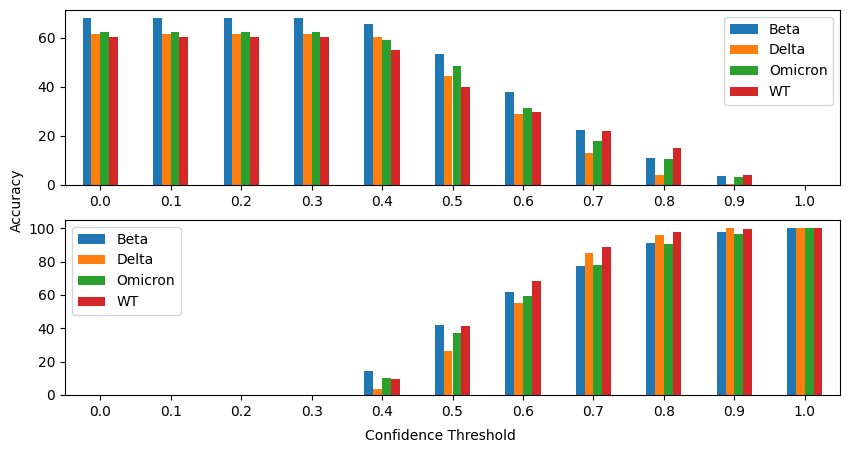

best conf is: 0.8
target:91.99361010465383 
and non target 19.765964251961357
avg = 55.879787178307595


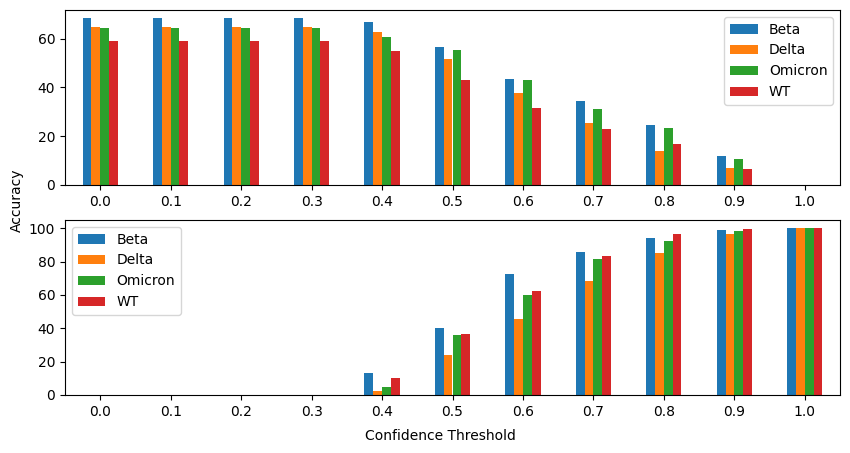

In [178]:
nt_results_df, t_results_df = run_confidence_scan(data_df,conf_vec)
loss = whats_the_best_results(nt_results_df, t_results_df,conf_vec)
ind = loss.index(min(loss))
best_conf = conf_vec[ind]
print(f'''best conf is: {best_conf}
target:{np.mean(t_results_df.iloc[ind])} 
and non target {np.mean(nt_results_df.iloc[ind])}
avg = {np.mean([np.mean(t_results_df.iloc[ind]), np.mean(nt_results_df.iloc[ind])])}''')

In [182]:
data_dict.keys()

dict_keys(['non_target_train_samples', 'non_target_test_samples', 'target_samples'])

In [142]:
confidence_threshold = 0.8

for t in targets_vec:
    _, _, model = LogReg_TTT(df=data_df, target=t, thr=confidence_threshold)

    avg_coef = np.mean(np.abs(model.coef_), axis=0)
    features_vec = [col for col in data_df.columns if col != 'target_vector']

    coef_df = pd.DataFrame({'Feature': features_vec,'Importance': avg_coef})
    sorted_coef_df = coef_df.sort_values(by='Importance', ascending=False)


confidence threshold = 0.8
test/train split size = 0.3
target variant = Beta

Performance on the test samples of the non_target dataset -> 24.77% [54/218]
Performance on the target samples -> 94.33% [266/282]
confidence threshold = 0.8
test/train split size = 0.3
target variant = Delta

Performance on the test samples of the non_target dataset -> 13.77% [34/247]
Performance on the target samples -> 84.95% [158/186]
confidence threshold = 0.8
test/train split size = 0.3
target variant = Omicron

Performance on the test samples of the non_target dataset -> 23.56% [53/225]
Performance on the target samples -> 92.25% [238/258]
confidence threshold = 0.8
test/train split size = 0.3
target variant = WT

Performance on the test samples of the non_target dataset -> 16.97% [37/218]
Performance on the target samples -> 96.45% [272/282]


<AxesSubplot: ylabel='Feature'>

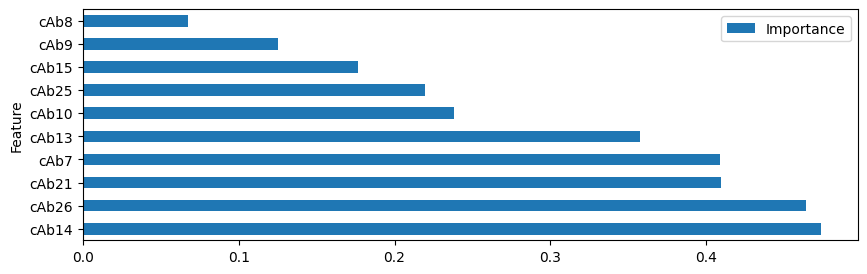

In [35]:
coefficients = model.coef_

nt_tr_X, nt_tr_y = Xy_split(data_dict['non_target_train_samples'])
t_X, t_y = Xy_split(data_dict['target_samples'])

avg_importance = np.mean(np.abs(coefficients), axis=0)
importance_df = pd.DataFrame({'Feature': nt_tr_X.columns,'Importance': avg_importance})
sorted_importance_df = importance_df.sort_values(by='Importance', ascending=False)

# Select the top 10 features
top_10_features = sorted_importance_df.head(10)

top_10_features.plot(x='Feature', y='Importance', kind='barh', figsize=(10, 3))
# sorted_importance_df.plot(x='Feature', y='Importance', kind='barh', figsize=(10, 6))


In [36]:
importance_df['dAb'] = importance_df['Feature'].apply(lambda x: re.search(r'dAb(\d+)', x).group(1))

dAb_importance = importance_df.groupby('dAb')['Importance'].sum()

sorted_dAb_importance=dAb_importance.sort_values(ascending=False)
sorted_dAb_importance.plot(x='Feature', y='Importance', kind='barh', figsize=(10, 3))


AttributeError: 'NoneType' object has no attribute 'group'

In [23]:
best_dAb = sorted_dAb_importance.index[0]

X_no_omicron_important_features = nt_tr_X[nt_tr_X.columns[pd.Series(nt_tr_X.columns).str.startswith('dAb'+best_dAb)]]
X_omicron_important_features = t_X[t_X.columns[pd.Series(t_X.columns).str.startswith('dAb'+best_dAb)]]

best_dAb

NameError: name 'sorted_dAb_importance' is not defined

In [30]:
df_important = pd.merge(X_omicron_important_features, nt_tr_y)
X_omicron_important_features

MergeError: No common columns to perform merge on. Merge options: left_on=None, right_on=None, left_index=False, right_index=False

In [ ]:
target = 'Delta'
lr_model3 = LogisticRegression(max_iter=1000)
lr_model3.fit(X_no_omicron_important_features, y_no_omicron)

omicron_results_all_2 = create_results(model=lr_model3, X=X_omicron_important_features, y=y_omicron)

print(target)
omicron_results_all_2['pred_confidence'] = omicron_results_all_2.apply(
    lambda row: row['pred_model'] if row['confidence_flag'] else target, axis=1)

omicron_perf_all_2 = sum(omicron_results_all_2['real'] == omicron_results_all_2['pred_confidence'] )/len(omicron_results_all_2)*100


print(f'''Performance in Finding {target}, with only dAb{best_dAb}:
{sum(omicron_results_all_2['real'] == omicron_results_all_2['pred_confidence'] )} correct prediction 
in {len(omicron_results_all_2)} total samples ({omicron_perf_all_2:.2f}%)\n''')

print(tabulate(omicron_results_all_2, headers='keys', tablefmt='psql', floatfmt=(".1f", ".2f", ".2f", ".2f")), '\n\n')
target


In [ ]:
conf_vec = [0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1]
targets_vec = ['Beta', 'Delta', 'Omicron', 'WT']
features_vec = [col for col in data_df.columns if col != 'target_vector']

nt_results_df = pd.DataFrame()
t_results_df = pd.DataFrame()

for t in targets_vec:
    print('-------')
    nt_perf_list = []
    t_perf_list = []
    
    model, data_dict = train_LogRegTTT_model(df=data_df, target=t)
    
    # feature coefs/importance
    avg_coef = np.mean(np.abs(model.coef_), axis=0)
    coef_df = pd.DataFrame({'Feature': features_vec,'Importance': avg_coef})
    
    # confidence screen results
    for c in conf_vec:
        nt_results = generate_results_df(model, data_dict['non_target_test_samples'], t, c)
        t_results = generate_results_df(model, data_dict['target_samples'], t, c)
        
        nt_perf = calculate_prefromance(nt_results)
        t_perf = calculate_prefromance(t_results)

        nt_perf_list.append(nt_perf)
        t_perf_list.append(t_perf)
        
    nt_results_df[t]= nt_perf_list 
    t_results_df[t]= t_perf_list 
    
nt_results_df.index = conf_vec
t_results_df.index = conf_vec
print('nt_results_df:\n', nt_results_df)
print('\n\nt_results_df:\n', t_results_df)